# **Aula 07 - Estatística Inferencial**

In [ ]:
import os

# Cria a estrutura de pastas exigida pelo roteiro no ambiente do Colab
os.makedirs('mtcars/data', exist_ok=True)

## 1. Preparando os dados

In [ ]:
# Importa as bibliotecas e define o tema dos gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="colorblind")

Este bloco prepara o ambiente importando as bibliotecas que vão ser usadas ao longo do notebook.

* **NumPy**: realiza cálculos numéricos com vetores.
* **pandas**: trabalha com tabelas. Lê o CSV, renomeia colunas, remove duplicatas, agrupa os dados e preenche lacunas.
* **Matplotlib**: cria as figuras e os painéis dos gráficos.
* **Seaborn**: construído sobre o Matplotlib, produz gráficos estatísticos, como histogramas e gráficos de barras.
* **SciPy**: fornece funções estatísticas, como a assimetria e calculo de p-valores, distribuições teóricas e índices de assimetria.

Por fim, `sns.set_theme` define um padrão visual para todos os gráficos do notebook: fundo branco com grade (`whitegrid`), que facilita a leitura dos valores, e uma paleta de cores acessível (`colorblind`).

In [ ]:
# Carrega a base e cria o rótulo do câmbio
mtcars = (
    pd.read_csv("mtcars/data/mtcars.csv")
    .assign(
        transmission=lambda df: np.where(
            df["am"] == 1,
            "Manual",
            "Automático",
        ),
    )
)

mtcars.head()

,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb,transmission
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4,Manual
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4,Manual
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1,Manual
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1,Automático
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2,Automático


O bloco é responsável por carregar o arquivo da base de dados que será usada.

## 2. A diferença observada

In [ ]:
# Tamanho, média, mediana e desvio-padrão do consumo por câmbio
(
    mtcars
    .groupby("transmission")
    .mpg
    .agg(["size", "mean", "median", "std"])
    .round(2)
)

,size,mean,median,std
transmission,,,,
Automático,19,17.15,17.3,3.83
Manual,13,24.39,22.8,6.17


Na tabela conseguimos identifica a quantidade de registros da base de dados,como a base tem poucos registro por grupo o peso deles na métricas se torna bem maior. Para os carros automáticos o valor da média e da mediana se mantém muito próximo, entretanto, nos carros manuais a diferença da média e da mediana é maior, o que pode identificar um outlier que está puxando a média para cima.

In [ ]:
# Efeito observado: diferença das médias de consumo
manual = mtcars.loc[mtcars.am == 1, "mpg"]
automatic = mtcars.loc[mtcars.am == 0, "mpg"]

delta_obs = manual.mean() - automatic.mean()

round(delta_obs, 2)

np.float64(7.24)

Aqui podemos ver o efeito que corresponde à diferença entre o consumo médio dos carros com câmbio manual e o dos carros com câmbio automático, após filtrar os valores por mpg para manual e automático calcula-se a média por grupo e subtrai a média dos automáticos da dos manuais para obter o delta. O delta é a favor dos manuais pois retorna valor positivo.

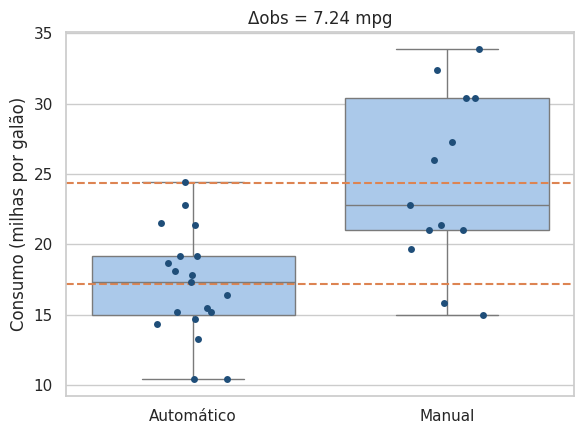

In [ ]:
# Boxplot com as observações sobrepostas e as médias de cada grupo
def plot_groups(data, x, y, order, ax, alpha=1, jitter=.15):
    sns.boxplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#A1C9F4",
        showfliers=False,
    )
    sns.stripplot(
        data=data, x=x, y=y, order=order, ax=ax,
        color="#1F4E79", alpha=alpha, jitter=jitter,
    )

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_groups(mtcars, "transmission", "mpg", ["Automático", "Manual"], ax)
for mean in [automatic.mean(), manual.mean()]:
    ax.axhline(mean, color="#DD8452", linestyle="--")
ax.set(title=f"Δobs = {delta_obs:.2f} mpg", xlabel="",
       ylabel="Consumo (milhas por galão)")
plt.tight_layout()
plt.show()

O gráfico ilustra a distribuição do consumo de combustível em mpg entre os grupos de carros automáticos e manuais, evidenciando o delta de 7,24 milhas por galão a favor dos veículos manuais que observamos anteriormente, no gráfico a faixa dos grupos quase não se sobrepõem, a faixa do grupo manual começa onde termina a do automático, e a média dos manuais está acima de praticamente todos os pontos dos automáticos. Embora os manuais sejam mais eficientes, existem valores extremos nas distribuições que se cruzam, alguns carros automáticos apresentam desempenho comparável ao de manuais, enquanto alguns carros manuais consomem tanto quanto automáticos, os carros manuais também possuem a maior assimetria, pois podemos notar os pontos mais disperso.

## 3. O problema da aleatoriedade


### 3.1 Um pronto-socorro simulado

In [ ]:
# Um ano de atendimentos diários, sem nenhum efeito da lua
rng = np.random.default_rng(2726)

full_moon_days = np.round(np.arange(12) * 29.53 + 14)

er_visits = (
    pd.DataFrame({"day": np.arange(365)})
    .assign(
        visits=rng.poisson(120, size=365),
        full_moon=lambda df: df["day"].isin(full_moon_days),
        moon=lambda df: np.where(df["full_moon"], "Lua cheia", "Demais dias"),
    )
)

Este bloco é responsável por simular os dados de atendimento de um pronto-socorro ao longo de um ano inteiro para testar o efeito da lua cheia nos plantões, como os números são gerados de forma aleatória garante-se que não existe nenhuma influência real da lua. O objetivo dessa simulação é servir como ponto de partida para entendermos como o acaso se comporta na prática e como evitar falsas conclusões na estatística.

In [ ]:
# Atendimentos por dia em cada grupo
(
    er_visits
    .groupby("moon")
    .visits
    .agg(["size", "mean", "median", "std"])
    .round(2)
)

,size,mean,median,std
moon,,,,
Demais dias,353,119.78,119.0,10.94
Lua cheia,12,123.67,121.5,9.36


Podemos ver nesse bloco que a média e mediana dos `Demais dias` se aproxima muito dos valores para `Lua cheia`, o que pode criar uma falsa ilusão de um padrão que não existe, e que apenas são valores naturalmente se parecem, mas que a lua cheia não é a motivação dos atendimentos.

In [ ]:
# Atendimentos de cada grupo e efeito observado da lua cheia
moon_in = er_visits.loc[er_visits.full_moon, "visits"]
moon_out = er_visits.loc[~er_visits.full_moon, "visits"]

moon_obs = moon_in.mean() - moon_out.mean()

round(moon_obs, 2)

np.float64(3.88)

Esse bloco é responsável por medir a diferença entre os dias de lua cheia e os demais dias, embora não tenha ligação comprovada a diferença entre eles é de 3,88 a mais nos dias de lua cheia, entretanto, é importante testar os dados para que essas pequenas variações não sejam interpretados de forma errada.

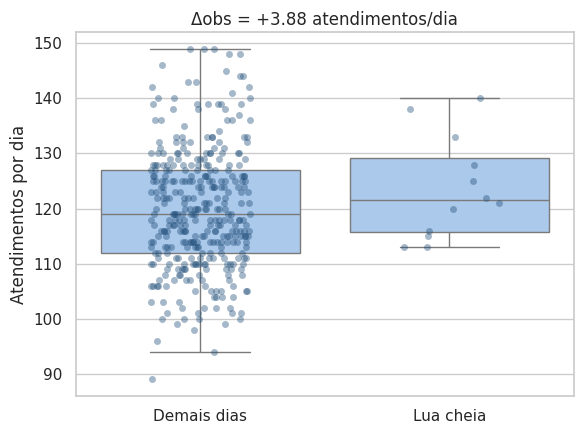

In [ ]:
# Atendimentos por grupo
fig, ax = plt.subplots(figsize=(6, 4.5))

plot_groups(
    er_visits, "moon", "visits", ["Demais dias", "Lua cheia"], ax,
    alpha=.4, jitter=.2,
)

ax.set(
    title=f"Δobs = {moon_obs:+.2f} atendimentos/dia",
    xlabel="",
    ylabel="Atendimentos por dia",
)

plt.tight_layout()
plt.show()

O gráfico faz a comparação do volume de atendimentos entre os dias de lua cheia e os demais dias, e embora tenha uma pequena variação média de +3,88 atendimentos por dia nos períodos de lua cheia, a distribuição dos pontos demonstram que os grupos são semelhantes e sobrepostos. Como a simulação foi feita sem efeito real da lua, então já sabemos que a diferença viria da variação natural. Com esse resultado podemos ver que o acaso é capaz de criar a ilusão de um padrão onde ele não existe e que podem ser apenas coincidência.

##4. Formalizando o acaso




### 4.1 Hipóteses nula e alternativa

### 4.2 O teste de permutação

In [ ]:
# Distribuição nula por permutação, aplicada à lua cheia
def permutation_null(values, labels, n_perm=10_000, seed=2026):
    rng = np.random.default_rng(seed)
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(labels)
        null.append(values[shuffled].mean() - values[~shuffled].mean())
    return np.array(null)

moon_values = er_visits["visits"].to_numpy()
moon_labels = er_visits["full_moon"].to_numpy()

moon_null = permutation_null(moon_values, moon_labels)

moon_null[:5].round(2)

array([-5.33, -6.46, -2.23, -1.54,  4.49])

Aqui ocorre a implementação do teste de permutação para construir a distribuição nula, permitindo assim avaliar se a diferença de atendimentos observada na lua cheia pode ser explicada apenas pelo acaso. A função permutation_null mistura aleatoriamente os rótulos dos dias de lua cheia recalculando a diferença de médias entre os grupos em cada cenário simulado. Após isso, se aplica essa função aos dados reais do pronto-socorro para gerar o vetor de resultados e exibir as primeiras simulações, para que assim possa ser comparado se a diferença é ou não um evento do acaso.

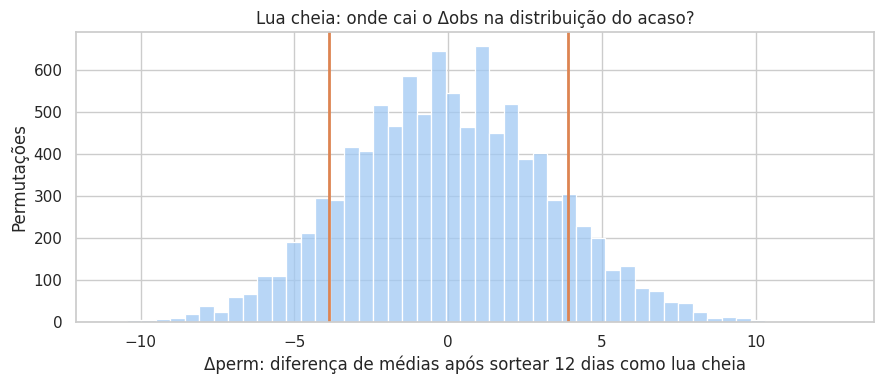

In [ ]:
# Distribuição nula da lua cheia e posição do efeito observado
def plot_null(null, obs, title, xlabel):
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(null, bins=50, color="#A1C9F4", ax=ax)
    for value in [-obs, obs]:
        ax.axvline(value, color="#DD8452", linewidth=2)
    ax.set(title=title, xlabel=xlabel, ylabel="Permutações")
    plt.tight_layout()
    plt.show()

plot_null(
    moon_null,
    moon_obs,
    title="Lua cheia: onde cai o Δobs na distribuição do acaso?",
    xlabel="Δperm: diferença de médias após sortear 12 dias como lua cheia",
)

Neste bloco, visualizamos a distribuição gerada pela permutações para avaliar se a diferença de médias observada na lua cheia é significativamente diferente do que pelo acaso. No gráfico tem a construção do histograma com as classes da distribuição simulada e usa de linhas verticais para identificar as posições simétricas de + e - Delta.
Se o delta observado cair no centro da distribuição, então o efeito da lua cheia não é estatisticamente distinguível de uma flutuação aleatória, entretanto, se a linha vertical fica nas caudas da distribuição, teremos evidências para rejeitar a hipótese nula, indicando que a diferença de médias associada à lua cheia é estatisticamente significativa.

### 4.5 Permutação no mtcars

In [ ]:
# Distribuição nula do câmbio
mpg_values = mtcars["mpg"].to_numpy()
mpg_labels = (mtcars["am"] == 1).to_numpy()

mpg_null = permutation_null(mpg_values, mpg_labels)

mpg_p = np.mean(np.abs(mpg_null) >= abs(delta_obs))

mpg_p

np.float64(0.0001)